* This notebook requires the use of pyNRC, which can be installed here along with its dependencies: https://pynrc.readthedocs.io/en/latest/installation.html

* This notebook was adapted from the pyNRC ramp optimization tutorial, which can be found here: https://pynrc.readthedocs.io/en/latest/tutorials/Ramp_Optimization_Examples.html


# Ramp Optimization Example for Exoplanet Coronagraphy

* This notebook outlines an example to optimize the ramp settings for a few different types of observations.

* In these types of optimizations, we must consider observations constraints such as saturation levels, SNR requirements, and limits on acquisition time.

* **Note**: The reported acquisition time does not include obsevatory and instrument-level overheads, such as slew times, filter changes, script compilations, etc. It only includes detector readout times (including reset frames).


In [1]:
# Import the usual libraries
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import os

%matplotlib inline

In [2]:
import pynrc
from pynrc import nrc_utils
#from pynrc.nrc_utils import S, jl_poly_fit
from pynrc.nrc_utils import jl_poly_fit

from pynrc.pynrc_core import table_filter

pynrc.setup_logging('WARNING', verbose=False)

from astropy.table import Table

# Progress bar
from tqdm.auto import tqdm, trange

**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


[     pynrc:INFO]   jwst_backgrounds is not installed and will not be used for bg estimates.


### We want to observe HIP 65426 b in the F430M filter using the MASK335R coronagraph. 

In [3]:
bp_k = pynrc.bp_2mass('ks')  # bandpass we want to normalize to, K-band in this case
filt = "F430M"  # filter we want to opitmize 

In [4]:
# get stellar spectra and normalize at K-Band
# the stellar_spectrum convenience function creates a synphot spectrum

source = 'HIP 65426 b'
dist = 108.88  # pc
age = 0.014*1000  # myr
mass = 7.1  # Mj
sp_star = pynrc.stellar_spectrum('A2V', 6.771, 'vegamag', bp_k)  # stellar spectrum in the K-band
planet = pynrc.planets_sb12(atmo='hy3s', mass=mass, age=age, entropy=8, distance=dist)   # 1500K, planet spectrum 
known_filt, mag = ['F410M', 15.330]  # known or estimated magnitude in a given filter, used for normalization

mask = "MASK335R"
pupil = 'CIRCLYOT'  # WEDGELYOT for the bar coronagraph
wind_mode, subsize = ('WINDOW', 160)  # 320 for LW bar
fov_pix, oversample = (160, 2)

sp_pl = planet.export_synphot()

# renormalize to known bandpass
bp_l = pynrc.read_filter(known_filt) # intialize bandpass
sp_pl = sp_pl.renorm(mag, 'vegamag', bp_l)  # renormalized planet spectrum

In [5]:
# initiate a NIRCam observation
nrc = pynrc.NIRCam(filter=filt, pupil_mask=pupil, image_mask=mask, 
                   wind_mode='WINDOW', xpix=320, ypix=320)

[webbpsf_ext.imreg_tools:INFO] Recentered oversampled PSF (-0.010, 1.204) pixels using Gaussian Fit algorithm.


In [6]:
if mask =="MASKLWB": 
    nrc.gen_wfemask_coeff(large_grid=False)

### The ramp optimization can be set up in two ways:
1. Defining a minumum SNR goal (120 for our example case) 
2. Defining an exposure time. In this case ``tacq_frac`` must be defined, which is a fraction by which the exposure time can exceed the defined maximum. The default is 0.1.

Examples of both are shown in the cell below. Setting ``even_nints=True``, provides you an even number of integrations that can be halved if two roll anlges are desired.  

In [7]:
# define maximum exposure time
#res = nrc.ramp_optimize(sp_pl, sp_bright=sp_star, tacq_max = 4000*2, tacq_frac = 0.05, even_nints=True, verbose=True) 

# define SNR goal
res = nrc.ramp_optimize(sp_pl, sp_bright=sp_star, snr_goal = 120, even_nints=True, verbose=True)


BRIGHT1
BRIGHT2
DEEP2
DEEP8
MEDIUM2
MEDIUM8
RAPID
SHALLOW2
SHALLOW4
 Pattern   NGRP NINT   t_int     t_exp     t_acq     SNR      Well     eff   
---------- ---- ---- --------- --------- --------- -------- -------- --------
DEEP8        13    2    265.12    530.24    532.42    169.7    0.035    7.354
DEEP2         8    2    151.80    303.61    305.79    121.2    0.020    6.932
DEEP2         6    4    109.04    436.17    440.52    137.7    0.014    6.562
SHALLOW4     10    8     52.38    419.06    427.78    129.4    0.007    6.255
SHALLOW2     10    8     50.24    401.96    410.67    120.5    0.007    5.944
MEDIUM8       4   12     40.62    487.48    500.55    124.8    0.005    5.579
MEDIUM2       5   12     44.90    538.80    551.86    125.7    0.006    5.349
BRIGHT2      10   32     21.38    684.19    719.03    121.9    0.003    4.545
BRIGHT1      10   44     20.31    893.72    941.63    119.3    0.003    3.888
BRIGHT1      10   46     20.31    934.34    984.43    122.0    0.003    3.

In [8]:
# display the Top 2 settings for each readout pattern
res2 = table_filter(res, 2)
print(res2)

 Pattern   NGRP NINT   t_int     t_exp     t_acq     SNR      Well     eff   
---------- ---- ---- --------- --------- --------- -------- -------- --------
RAPID        10  154     10.69   1646.32   1814.02    120.3    0.001    2.824
RAPID        10  156     10.69   1667.70   1837.58    121.1    0.001    2.824
BRIGHT1      10   44     20.31    893.72    941.63    119.3    0.003    3.888
BRIGHT1      10   46     20.31    934.34    984.43    122.0    0.003    3.888
BRIGHT2      10   32     21.38    684.19    719.03    121.9    0.003    4.545
SHALLOW2     10    8     50.24    401.96    410.67    120.5    0.007    5.944
SHALLOW4     10    8     52.38    419.06    427.78    129.4    0.007    6.255
MEDIUM2       5   12     44.90    538.80    551.86    125.7    0.006    5.349
MEDIUM8       4   12     40.62    487.48    500.55    124.8    0.005    5.579
DEEP2         8    2    151.80    303.61    305.79    121.2    0.020    6.932
DEEP2         6    4    109.04    436.17    440.52    137.7    0

### Now we can update the detector with our desired settings. 
We can play around with the various readout patterns, number of groups, number of integrations, etc., and see how those would affect our observations. The SHALLOWs, DEEPs, and MEDIUMs are very similar for SNR and efficiency.

In [9]:
read_mode = 'MEDIUM8'
ngroup=4
nint=12

nrc.update_detectors(read_mode=read_mode, ngroup=ngroup, nint=nint)

keys = list(nrc.multiaccum_times.keys())
keys.sort()
for k in keys:
    print("{:<10}: {: 12.5f}".format(k, nrc.multiaccum_times[k]))

t_acq     :    500.54976
t_exp     :    487.48224
t_frame   :      1.06904
t_group   :     10.69040
t_int     :     40.62352
t_int_tot1:     41.71248
t_int_tot2:     41.71248


In [10]:
# calculate the sensitivity of your desired settings to a given sigma value
sens_dict = nrc.sensitivity(nsig=5, units='vegamag', verbose=True)


Point Source Sensitivity (5-sigma): 18.96 vegamag
Surface Brightness Sensitivity (5-sigma): 20.18 vegamag/arcsec^2


# Create a Mock Observation
For the purposes of this tutorial, we are assuming a perfect reference match to HIP 65426 with identical parameters. If you have a reference star in mind, you can create a new stellar spectrum for your reference star. 

When generating your obs_hci object, ``large_grid=True`` will produce higher fidelity PSF variations across the FoV, but is very slow (30+min to a few hours). For the purposes of this tutorial, we will set ``large_grid=False``.

In [11]:
sp_sci = sp_star  # take stellar spectrum for HIP 65426 defined in previous section
sp_ref = sp_star  # take stellar spectrum for HIP 65426 defined in previous section

In [12]:
# can define an offset for the bar coronagraph if the narrow offset is desired. If not, set to None.
bar_offset = None  # 8 for LW narrow offset

# mask, pupil, wind_mode, subsize, and fov_pix all defined in previous section
obs = pynrc.obs_hci(sp_sci, dist, sp_ref=sp_ref, use_ap_info=False,
                        filter="F430M", image_mask=mask, pupil_mask=pupil, bar_offset = bar_offset, 
                        wind_mode=wind_mode, xpix=subsize, ypix=subsize, 
                        fov_pix=fov_pix, oversample=oversample, large_grid=False)


[webbpsf_ext.imreg_tools:INFO] Recentered oversampled PSF (-0.010, 1.204) pixels using Gaussian Fit algorithm.


In [13]:
# update the detector with our observation settings
obs.update_detectors(read_mode=read_mode, ngroup=ngroup, nint=nint, verbose=True)

# update detector for the reference object 
obs.gen_ref_det(read_mode=read_mode, ngroup=ngroup, nint=nint)

New Ramp Settings
  read_mode  :  MEDIUM8
  nf         :        8
  nd2        :        2
  ngroup     :        4
  nint       :       12
New Detector Settings
  wind_mode  :   WINDOW
  xpix       :      320
  ypix       :      320
  x0         :     1237
  y0         :     1512
New Ramp Times
  t_group    :   10.690
  t_frame    :    1.069
  t_int      :   40.624
  t_int_tot1 :   41.712
  t_int_tot2 :   41.712
  t_exp      :  487.482
  t_acq      :  500.550


### Let's add our companion to the observation. 
If mulitple planets are present in the system, more values can be added to each variable list. 

In this case, the planet location was calculated for September 2027 using http://whereistheplanet.com.

In [14]:
loc_list = [(0.422915, -0.681604)]  # planet location, (RA, dec)

mass = [7.1]  # Mj
age=0.014*1000  # myr
pmags = [15.32]  # estimated planet magnitudes in the filter of choice
    
# add planet information to observation class
# these are stored in obs.planets andf can be cleared using obs.delete_planets()
obs.delete_planets()
for i, loc in enumerate(loc_list):
    obs.add_planet(model='SB12', mass=mass[i], entropy=8, age=age, xy=loc, runits='arcsec',
                   renorm_args=(pmags[i], 'vegamag', obs.bandpass))

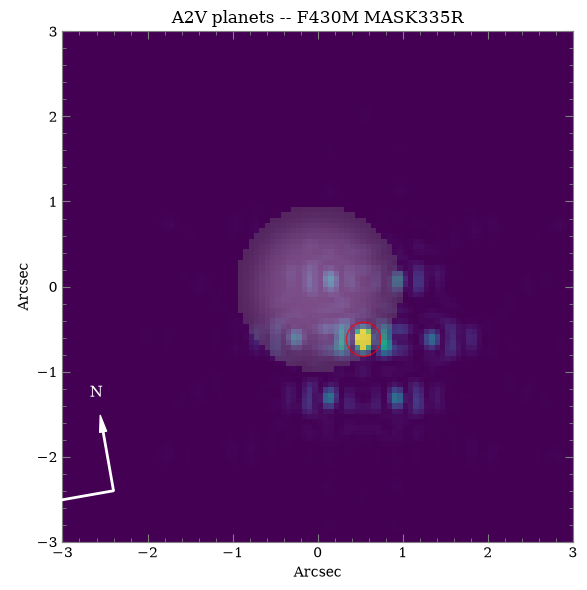

In [15]:
from matplotlib.patches import Circle
from pynrc.nrc_utils import plotAxes
from pynrc.obs_nircam import get_cen_offsets


# generate and plot a noiseless slope image to verify orientation
PA1, PA2 = (85,95)  #  position angles for our two rolls

PA_offset = 10  # Image field is rotated opposite direction
im_planets = obs.gen_planets_image(PA_offset=PA_offset, return_oversample=False)




fig, ax = plt.subplots(figsize=(6,6))

xasec = obs.det_info['xpix'] * obs.pixelscale
yasec = obs.det_info['ypix'] * obs.pixelscale
extent = [-xasec/2, xasec/2, -yasec/2, yasec/2]
xylim = 3

vmin = 0
vmax = 0.5*im_planets.max()
ax.imshow(im_planets, extent=extent, vmin=vmin, vmax=vmax)

# Overlay the coronagraphic mask
detid = obs.Detector.detid
im_mask = obs.mask_images['DETSAMP']
# Do some masked transparency overlays
masked = np.ma.masked_where(im_mask>0.95*im_mask.max(), im_mask)
ax.imshow(1-masked, extent=extent, alpha=0.3, cmap='Greys_r', vmin=-0.5)


for loc in loc_list:
    xc, yc = get_cen_offsets(obs, idl_offset=loc, PA_offset=PA_offset)
    circle = Circle((xc,yc), radius=xylim/15., alpha=0.7, lw=1, edgecolor='red', facecolor='none')
    ax.add_artist(circle)

xlim = ylim = np.array([-1,1])*xylim
xlim = xlim + obs.bar_offset
ax.set_xlim(xlim)
ax.set_ylim(ylim)

ax.set_xlabel('Arcsec')
ax.set_ylabel('Arcsec')

ax.set_title('{} planets -- {} {}'.format(sp_sci.name, obs.filter, obs.image_mask))

color = 'grey'
ax.tick_params(axis='both', color=color, which='both')
for k in ax.spines.keys():
    ax.spines[k].set_color(color)

plotAxes(ax, width=1, headwidth=5, alength=0.15, angle=PA_offset,
                   position=(0.1,0.1), label1='E', label2='N')

fig.tight_layout()

# Generate contrast curves

In [16]:
nsig = 5
roll_angle = np.abs(PA2 - PA1)
wfe_list = [0,5,10]

curves = []
for wfe_drift in tqdm(wfe_list):
    # assume drift between Roll1 and Roll2 is 2 nm WFE
    wfe_roll_drift = 0 if wfe_drift<2 else 2

    # generate contrast curves
    result = obs.calc_contrast(roll_angle=roll_angle, nsig=nsig,
                               wfe_ref_drift=wfe_drift, wfe_roll_drift=wfe_roll_drift,
                               xyoff_roll1=(0,0), xyoff_roll2=(0,0), xyoff_ref=(0,0))
    curves.append(result)


  0%|          | 0/3 [00:00<?, ?it/s]

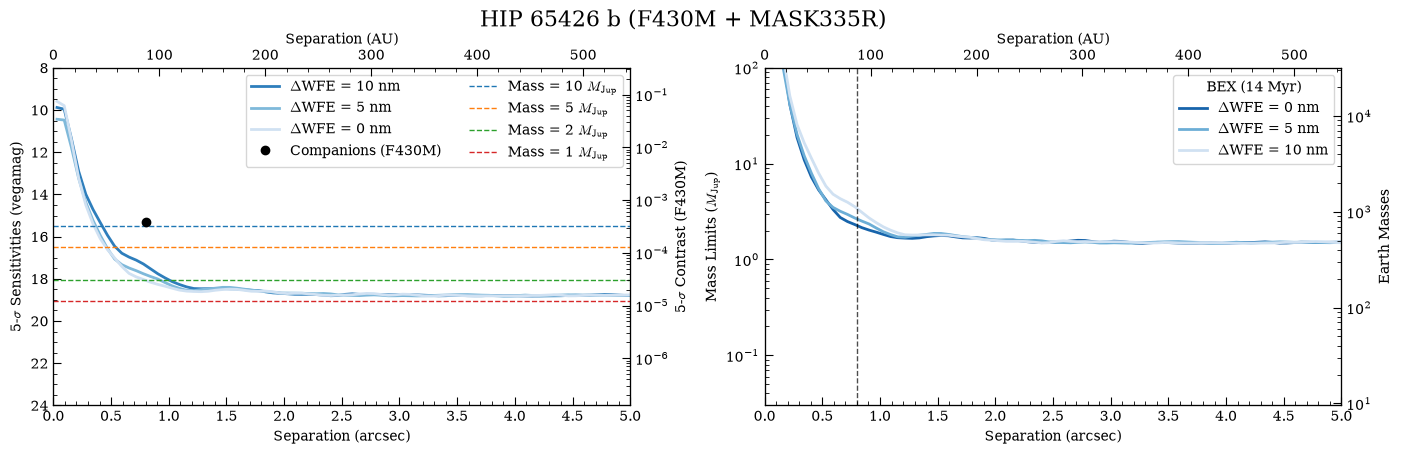

In [17]:
from pynrc.nb_funcs import plot_contrasts, plot_planet_patches, plot_contrasts_mjup, update_yscale
import matplotlib.patches as mpatches

# fig, ax = plt.subplots(figsize=(8,5))
fig, axes = plt.subplots(1,2, figsize=(14,4.5))
xr=[0,5]
yr=[24,8]

# 1a. plot contrast curves and set x/y limits
ax = axes[0]
ax, ax2, ax3 = plot_contrasts(curves, nsig, wfe_list, obs=obs,
                              xr=xr, yr=yr, ax=ax, return_axes=True)
# 1b. plot the locations of exoplanet companions
label = 'Companions ({})'.format(filt)
planet_dist = [np.sqrt(x**2+y**2) for x,y in loc_list]
ax.plot(planet_dist, pmags, marker='o', ls='None', label=label, color='k', zorder=10)

# 1c. plot Spiegel & Burrows (2012) exoplanet fluxes (Hot Start)
plot_planet_patches(ax, obs, age=age, entropy=13, av_vals=None)
ax.legend(ncol=2)

# 2. plot in terms of MJup using COND models
ax = axes[1]
ax1, ax2, ax3 = plot_contrasts_mjup(curves, nsig, wfe_list, obs=obs, age=age,
                                    ax=ax, twin_ax=True, xr=xr, yr=None, return_axes=True)
yr = [0.03,100]
for xval in planet_dist:
    ax.plot([xval,xval],yr, lw=1, ls='--', color='k', alpha=0.7)
update_yscale(ax1, 'log', ylim=yr)
yr_temp = np.array(ax1.get_ylim()) * 318.0
update_yscale(ax2, 'log', ylim=yr_temp)
# ax.set_yscale('log')
# ax.set_ylim([0.08,100])
ax.legend(loc='upper right', title='BEX ({:.0f} Myr)'.format(age))

fig.suptitle('{} ({} + {})'.format(source, obs.filter, obs.image_mask), fontsize=16)

fig.tight_layout()
fig.subplots_adjust(top=0.85, bottom=0.1 , left=0.05, right=0.97)